**Exercise overview:** Minimize a funtion using gradient descent

## Q12 - NN

### b
_Neural networks training (Gradients, the chain rule and back/forward propagation)_

**Neural networks training**
- **Goal:** Minimize loss function
- **Forward Propagation:** Passes weighted sums through activation functions to make predictions.
- Calculate loss
- **Backward Propagation:** Calculate gradients of error with respect to each weight

**Backwards Propagation**
- NN is like a composition of functions
- Use chain rule to calculate gradients back through the neural networs
- $\frac{\partial J(W)}{\partial w_1} = \frac{\partial J(W)}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial z_1} \cdot \frac{\partial z_1}{\partial w_1}$

**Gradient Descent**
- Update weights using Gradient descent
- Compute the gradient of the loss function with respect to the model parameters:
    - The gradient points towards the **steepest increase (uphill)**.
    - To minimize the loss, move in the **negative gradient direction (downhill)**.
- Adjust the model parameters in this direction, scaled by the learning rate.
- Repeat the steps until the loss stops decreasing significantly or reaches a satisfactory value.

**Issues with Gradient Descent**
- **Too Small Learning Rate**: Slow or get stuck in local minimum
- **Too Large Learning Rate**: The algorithm might overshoot the minimum or keep going around it, never converging.

**Optimizations**
- **Stochastic Gradient Descent**
    - Predict only on a small subset of the data each time
    - Introduces noise, which might help escape local minimums
- **Momentum**
    - Combine current gradient and previous update

# Non-Linear Optimization: Multivariable Functions
In this exercise, the goal is to minimize the function

$$
f(x, y) = e^{-x^2 - y^2} \sin(x) \cos(y),
$$
which combines exponential decay with sinusoidal variations. This makes it a compelling case for gradient descent optimization.
Unlike typical loss functions used in machine learning, where minimization is performed with respect to model parameters and data, here the aim is directly to find the values of $x$ and $y$ that minimize $f(x, y)$. In this context, $f(x, y)$ serves as a measure of error when evaluated with respect to the model parameters. Besides $x$ and $y$ are not treated as model parameters but simply as variables within the mathematical function.
## Steps
The following steps will be needed
- Compute partial derivatives to calculate the gradient in a point.
- Calculating forward (prediction) and backward (gradient steps) passes of the function.
- Iteratively using the forward and backward passes to optimize the function.


<article class="message">
    <div class="message-body">
        <strong>List of individual tasks</strong>
        <ul style="list-style: none;">
            <li>
            <a href="#forward">Task 1: Forward pass</a>
            </li>
            <li>
            <a href="#testing">Task 2: Explain the function</a>
            </li>
            <li>
            <a href="#partial">Task 3: Backward pass pen and paper</a>
            </li>
            <li>
            <a href="#partial1">Task 4: Backward implementation</a>
            </li>
            <li>
            <a href="#partial2">Task 5: Gradient descent</a>
            </li>
            <li>
            <a href="#plotting">Task 6: Optimization path</a>
            </li>
            <li>
            <a href="#reflection">Task 7: Reflection</a>
            </li>
        </ul>
    </div>
</article>

## Class Implementation
The function $f(x, y)$ and its gradient descent optimization will be implemented within the `ExpTrig`
 class defined in the cell below
The class includes the following methods, which must be implemented in the subsequent tasks.
1. `forward`
  must return the function value of `f(x,y)`
 e.g., the predictions
2. `df_dx`
  must return the partial derivative of the function with respect to `x`

3. `df_dy`
 must return the partial derivative of the function with respect to `y`

4. `backward`
 must return the gradient of `f(x,y)`
 as a tuple `(df_dx, df_dy)`
. The naming 'backward' is used due to its reference to backpropagation.
5. `display_function`
 makes a figure of the function defined in `forward`
.



In [4]:
# import packages
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

class ExpTrig:

    # predictions (forward pass through the network)
    def forward(self, x, y):
        """
        Args:
        x: x-values (Can be single float or 1D array)
        y: y-values (Can be single float or 1D array)

        Returns:
        The function values of f (size-like x and y)
        """
        
        # solve the function with the given x and y values
        x = np.asarray(x)
        y = np.asarray(y)
        return np.exp(-x**2 - y**2) * np.sin(x) * np.cos(y)
    

    def df_dx(self, x,y):
        """
        Args:
        x: x-values (Can be single float or 1D numpy array)
        y: y-values (Can be single float or 1D numpy array)

        Returns:
        The partial derivative of f with respect to x (size-like x and y)
        """
        # using product rule and chain rule 
        return np.exp(-x**2 - y**2) * (np.cos(x) * np.cos(y) - 2*x*np.sin(x) * np.cos(y))
        

    def df_dy(self, x,y):
        """
        Args:
        x: x-values (Can be single float or 1D numpy array)
        y: y-values (Can be single float or 1D numpy array)

        Returns:
        The partial derivative of f with respect to y (size-like x and y)
        """
        # using product rule and chain rule 
        return np.exp(-x**2 - y**2) * (-np.sin(x) * np.sin(y) + 2*y*np.sin(x) * np.sin(y))

    # the gradient at point (x, y)
    def backward(self, x, y):
        """
        args:
        x: x-values
        y: y-values
        Returns:
        Patial derivatives of the function (i.e. the gradient) as a tuple
        """
        return (self.df_dx(x, y), self.df_dy(x, y))

    def display_function(self):
        
        x = np.linspace(-2, 2, 400)
        y = np.linspace(-2, 2, 400)
        x, y = np.meshgrid(x, y)

        z = self.forward(x,y)

        # Create a 3D plot  
        fig = plt.figure(figsize=(10, 8))
        ax = fig.add_subplot(111, projection='3d')
        ax.plot_surface(x, y, z, cmap='viridis', alpha=0.8)
        ax.set_xlabel('X axis')
        ax.set_ylabel('Y axis')
        ax.set_zlabel('f(x, y)')
        ax.set_title('Surface of f(x, y) = e^{-x^2 - y^2} sin(x) cos(y)')
        plt.show()


---
**Task 1 (easy): Forward pass👩‍💻**
1. Implement the  `forward`
 function in the class.
2. Run the cell below to visualize the function. 


---

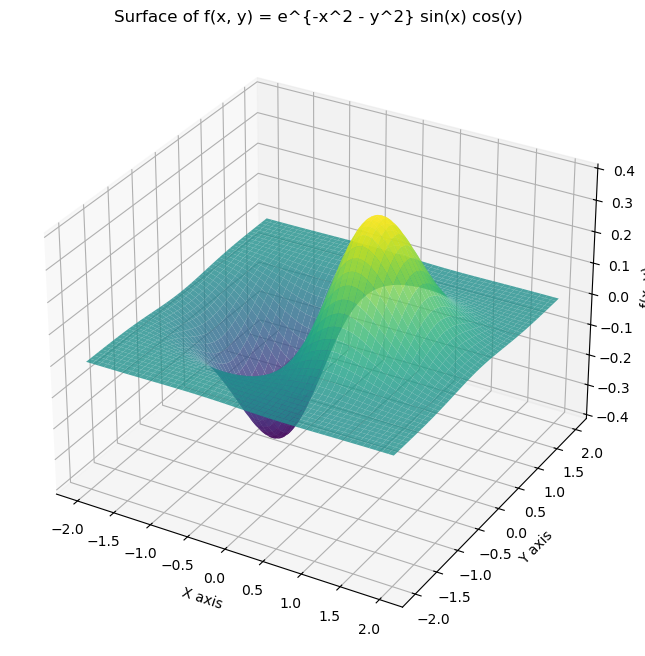

In [5]:
# Grid of x, y points
f = ExpTrig()

f.display_function()


---
**Task 2 (easy): Explain the function💡**
Use the plot to identify the minima of the function and discuss potential challenges associated with gradient-based optimization.

---

In [6]:
# A lot of flat surfaces might lead to vanishing gradients, where the gradient is close to zero causing the optimazation to become very slow
# The gradient descent might consider the flat surface as a local minimum and stop there
# The same goes for maximum

## Gradient Descent
**Gradient Descent** is an iterative optimization method that updates input variables step by step by using the gradient of a function with respect to these variables. The updates are made by moving in the negative direction of the gradient, which corresponds to the direction of the steepest decrease in the function's value. The update rule is given by:

$$ x_{t+1} = x_t - \lambda \nabla_x f(x_t) $$
where:
- $x_t \in \mathbb{R}^n$ represents the input to the function $f(x)$ at iteration $t$,
- $x_{t+1}$ is the updated input at iteration $t+1$,
- $\nabla_x f(x_t)$ is the gradient of $f$ with respect to $x$ at $x_t$,
- $\lambda$ is the learning rate, which controls the size of each step, and
- $t$ is the current iteration step.


---
**Task 3 (medium): Backward pass pen and paper♾️**
On a piece of paper, show that the partial derivatives of the function $f(x, y)$ with respect to $x$ and $y$, i.e.,
$\frac{\partial f}{\partial x} \quad \text{and} \quad \frac{\partial f}{\partial y}$ are 

$$

\frac{\partial f}{\partial x} = -2xe^{-x^2 - y^2} \sin(x) \cos(y) + e^{-x^2 - y^2} \cos(x) \cos(y) 

$$

$$

\frac{\partial f}{\partial y} = -2ye^{-x^2 - y^2} \sin(x) \cos(y) - e^{-x^2 - y^2} \sin(x) \sin(y) 

$$

**Hint**
Recall the _chain rule_ and and _product rule_ for finding the partial derivatives for $x$ and $y$.


---


---
**Task 4 (medium): Backward implementation👩‍💻**
Implement the following functions in the `ExpTrig`
 class:
1. `df_dx`
 and `df_dy`
  which return the values of the partial derivatives for a given `x`
 and `y`
. See the results in the previous task (in case you didn't complete the previous task the result is given there)


2. `backward`
 method so that it returns the gradient evaluated at a given x, y.



---

In [7]:
# Write your solution here

## Optimization Method

---
**Task 5 (medium): Gradient descent👩‍💻**
The following steps outline the implementation of gradient descent for the function $f(x, y)$ , which is defined in the `ExpTrig`
 class. The implementation of `optimize_function`
 method involves several tasks that must be completed. Implement each of these steps in the cell below.
1. **Initialize Coordinates**: Start by initializing `x`
 and `y`
 as `start_x`
 and `start_y`
, respectively. These are your starting guesses for the optimization.

2. **Initialize History Lists**: Create two lists, `x_all`
 and `y_all`
, to record the coordinates visited during the optimization.

3. **Start Gradient Descent Loop**: Implement a for-loop that iterates a specified number of times. Within each iteration:
    - Use the `backward`
 method of `func`
 to compute the gradients at the current estimate `(x, y)`
.
    - Update `x`
 and `y`
 using the optimization steps by taking a step in the direction opposite to the gradient, scaled by the `learning_rate`
. 
    - Logging (optional): Add a logging mechanism to display the current state of the optimization. For example, print the iteration number, values `x`
, `y`
, and the function value, $f(x,y)$ at these coordinates every 25 iterations.
    - Record History: append the current values of `x`
 and `y`
 to `x_all`
 and `y_all`
, respectively.


4. **Return the Result**: the function should return `x_all`
 and `y_all`
.



---

In [33]:
def optimize_function(func, start_x, start_y, learning_rate, iterations):
    """
    Optimize a given function using gradient descent.

    Args:
    - func (Function): A function object that must have 'forward' and 'backward' methods.
                       The 'forward' method computes the function value at a given point (x, y),
                       and the 'backward' method computes the gradient at that point.
    - start_x (float): The starting x-coordinate for the optimization.
    - start_y (float): The starting y-coordinate for the optimization.
    - learning_rate (float): The step size for each iteration in the gradient descent.
    - iterations (int): The total number of iterations for the optimization process.

    Returns:
    - x_all (list of float): List of all x-coordinates of the points visited during the optimization.
    - y_all (list of float): List of all y-coordinates of the points visited during the optimization.

    This function performs gradient descent on the provided function object. Starting from 
    (start_x, start_y), it iteratively moves in the direction opposite to the gradient, 
    with step sizes determined by the learning rate. The function's value and current 
    coordinates are printed every 25 iterations. The function returns the history of 
    coordinates visited during the optimization.
    """
    # Initialize starting point
    x = start_x
    y = start_y
    
    # Initialize history of points visited
    x_all = [x]
    y_all = [y]
    
    # Iterate a specified number of times
    for i in range(iterations):
        # Compute the gradient at the current point
        grad_x, grad_y = func.backward(x, y)
        
        # Update the current point in the opposite direction of the gradient
        x -= learning_rate * grad_x
        y -= learning_rate * grad_y
        
        # Logging every 25 iterations
        if i % 25 == 0:
            print(f"Iteration {i}: f({x}, {y}) = {func.forward(x, y)}")
        
        # Append the current point to the history
        x_all.append(x)
        y_all.append(y)
    
    return x_all, y_all

# Example optimization
x_arr, y_arr = optimize_function(ExpTrig(), start_x=-1.5, start_y=-1.4, learning_rate=0.2, iterations=100)

Iteration 0: f(-1.4985254553748546, -1.3889087876593937) = -0.00277488321873563
Iteration 25: f(-1.3372795858396633, -0.9365104971967149) = -0.04011051818831364
Iteration 50: f(-0.6546955301799088, -0.10144207693307782) = -0.390572019947414
Iteration 75: f(-0.653271199733914, -0.010823176186930785) = -0.39658327018313666



---
**Task 6 (medium): Optimization path💡**
1. Run the cell below to plot the optimization path of the `optimize_function`
.
2. Identify areas where the optimization slows down or oscillates and explain why might these occur?
3. How might a different learning rate affect the optimization path? Consider the possibilities of paths that overshoot, oscillate, or stagnate.
4. How does the shape of the surface (e.g., steep slopes or flat regions) influence the behavior of the optimization path?


---

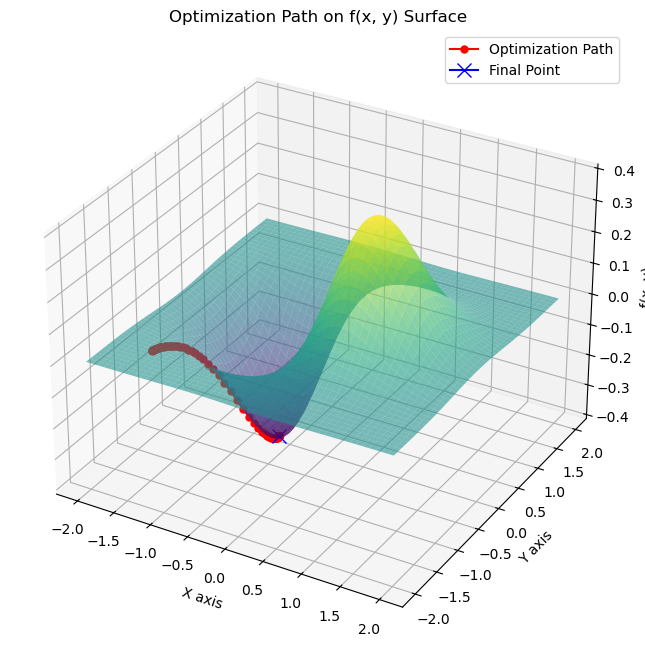

In [34]:
x = np.linspace(-2, 2, 400)
y = np.linspace(-2, 2, 400)
x, y = np.meshgrid(x, y)
z = ExpTrig().forward(x,y)

# Assuming you have lists `x_values` and `y_values` containing the optimization path
x_values = np.array(x_arr)
y_values = np.array(y_arr)
z_values = np.exp(-np.array(x_values)**2 - np.array(y_values)**2) * np.sin(x_values) * np.cos(y_values)

# Plot the optimization path on the surface
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x, y, z, cmap='viridis', alpha=0.6)
ax.plot(x_values, y_values, z_values, marker='o', color='r', markersize=5, label='Optimization Path')
ax.plot(x_values[-1], y_values[-1], z_values[-1], marker='x', color='b', markersize=10, label='Final Point')
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_zlabel('f(x, y)')
ax.set_title('Optimization Path on f(x, y) Surface')
ax.legend()
plt.show()

In [35]:
## Areas where the optimization slows down
# At the beginning in the flat areas, the optimization slows down because the gradient is close to zero
# Towards the end, the optimization slows down as it approaches the local minimum so the gradient becomes smaller and smaller
# How big a step to take is determined by the learning rate scaled by the gradient, so both the learning rate and the gradient affect the speed of optimization

## How the learning rate affects the optimization
# Smaller: 
## Pros: 
# - The optimization is more stable and less likely to overshoot the minimum
## Cons:
# - The optimization is slower, especially in the flat areas

# Larger:
## Pros:
# - The optimization is faster
## Cons:
# - The optimization is less stable and more likely to overshoot the minimum becuase it "steps over it" and then oscillates around it

## How does the surface of the function affect the optimization
# Flat regions: Make the optimization slower because the gradient is close to zero. Can cause stagnation
# Steep regions: Make the optimization faster because the gradient is larger. Can cause overshooting
# If there are many local minima, the optimization might get stuck in a local minimum instead of finding the global minimum


---
**Task 7 (medium): Reflection💡**
Assess the proficiency of the of the gradient descent algorithm
1. Use gradient descent to find the minimum using the following starting points:


$$
x_{0}=1.5, y_{0}=1.5 
$$

$$
x_{0}=-1.5, y_{0}=-1.5
$$

$$
x_{0}=-1.0, y_{0}=1.3
$$

$$
x_{0}=1.2, y_{0}=-1.5
$$
2. In the cell below describe the main observations from these optimizations.
3. Explain why the optimization process sometimes fails to find the **global** minimum?
4. Use different learning rates (try 0.1, 0.5, 1.0) and discuss how they affect the results.
5. List two issues commonly encountered in gradient descent optimization and provide a potential solution for each problem:    - Describe each issue and explain why it poses a challenge.
    - Propose a potential solution to address each issue effectively.




---

In [36]:
# Find minimum with different starting points
x_arr1, y_arr1 = optimize_function(ExpTrig(), start_x=1.5, start_y=1.5, learning_rate=0.2, iterations=100)
print(f"Starting point: (1.5, 1.5)")
print(f"Final point 1: ({x_arr1[-1]}, {y_arr1[-1]}) = {ExpTrig().forward(x_arr1[-1], y_arr1[-1])}")
print()

x_arr2, y_arr2 = optimize_function(ExpTrig(), start_x=-1.5, start_y=-1.5, learning_rate=0.2, iterations=100)
print(f"Starting point: (-1.5, -1.5)")
print(f"Final point 2: ({x_arr2[-1]}, {y_arr2[-1]}) = {ExpTrig().forward(x_arr2[-1], y_arr2[-1])}")
print()

x_arr3, y_arr3 = optimize_function(ExpTrig(), start_x=-1., start_y=1.3, learning_rate=0.2, iterations=100)
print(f"Starting point: (-1, 1.3)")
print(f"Final point 3: ({x_arr3[-1]}, {y_arr3[-1]}) = {ExpTrig().forward(x_arr3[-1], y_arr3[-1])}")
print()

x_arr4, y_arr4 = optimize_function(ExpTrig(), start_x=1.2, start_y=-1.5, learning_rate=0.2, iterations=100)
print(f"Starting point: (1.2, -1.5)")
print(f"Final point 4: ({x_arr4[-1]}, {y_arr4[-1]}) = {ExpTrig().forward(x_arr4[-1], y_arr4[-1])}")
print()


Iteration 0: f(1.500459193172242, 1.4955786360488275) = 0.0008426819960726533
Iteration 25: f(1.525939912103984, 1.3761511875587702) = 0.0028336469594851497
Iteration 50: f(1.5883454486376396, 1.251026884777476) = 0.005272139032975523
Iteration 75: f(1.6882795208684407, 1.1440649130824643) = 0.0064207126998384765
Starting point: (1.5, 1.5)
Final point 1: (1.7977465281865084, 1.0709360440473568) = 0.005856539217560053

Iteration 0: f(-1.499540806827758, -1.491157272097655) = -0.0009064076361984556
Iteration 25: f(-1.4380970354747549, -1.1684027523624574) = -0.012530656034307407
Iteration 50: f(-0.7302431865141096, -0.2832785283332552) = -0.3467807220759689
Iteration 75: f(-0.6532721920470852, -0.024196522829693715) = -0.39630475904135515
Starting point: (-1.5, -1.5)
Final point 2: (-0.6532711871079273, -0.003184952565722073) = -0.396646925702436

Iteration 0: f(-0.9958503733961681, 1.3176122528805314) = -0.013739979358950265
Iteration 25: f(-0.9724546879452444, 1.6544072610159504) = 0.0

In [37]:
# Main observations:
# - The optimization process is sensitive to the starting point
# - Many ends up around 0, which is the flat area

# Why does it sometimes fail to find the global minimum?
# - Starting at a flat area, the optimization might get stuck in a local minimum
# - Not enough iterations or too small learning rate, it might too slow to reach the global minimum
# - The optimization might overshoot the global minimum and then oscillate around it

# How the learning rate affects the optimization
# - Smaller learning rate: Slower optimization, but more stable. Might be too slow in flat areas
# - Larger learning rate: Faster optimization, but might overshoot the minimum

# Common problems with gradient descent
# - Vanishing gradients: The gradient is close to zero, causing the optimization to become very slow
# - Local minima: The optimization might get stuck in a local minimum instead of finding the global minimum
# Use eg. momentum, adaptive learning rates, etc. to mitigate these problems
